In [1]:
# ADMS 4509 A, F26
# Dr. Hamid Arian
# Term 2 Group Project
# Part 6: EVT-based VaR and ES
# Zakariya Asif

In [2]:
# Inspecting whether working directory is the project root or ../src
from pathlib import Path
import pandas as pd

print("Notebook working directory:", Path.cwd())

Notebook working directory: C:\Users\zakar\Jupyter_Projects\4509_EVT\src


In [3]:
# Checking if I have openpyxl in my environment
import openpyxl
print(openpyxl.__version__)

3.1.5


In [4]:
# Working directory is ../4509_EVT/src
project_root = Path.cwd().parent

In [5]:
# Attempting to read the .xlsx file provided by Rowan
data_path = (
    project_root
    / "data"
    / "5 Year Historical Stock Price Data - ADMS4509.xlsx"
)

if not data_path.is_file():
    raise FileNotFoundError(f"Worbook not found: {data_path}")

tickers = ["AMZN", "WMT", "JPM", "JNJ", "MSFT"]

raw_returns = pd.read_excel(
    data_path,
    sheet_name="Daily Returns",
    header=1, ## The column names are on the second Excel row
    usecols=["Date", *tickers],
    engine="openpyxl",
)

raw_returns.head()

,Date,AMZN,WMT,JPM,JNJ,MSFT
0,2026-11-16,-0.033984,0.002495,-0.023321,-0.011262,-0.011307
1,2026-11-13,-0.002921,0.014944,0.009782,0.007835,0.001681
2,2026-11-12,0.004760,0.004129,-0.001661,0.011030,0.003582
3,2026-11-11,-0.017504,0.000955,0.003851,-0.001319,-0.022822
4,2026-11-10,0.014653,-0.000876,-0.000029,-0.004726,-0.022294


In [6]:
# Validating prior to cleansing
# Keeping the imported data separate from the cleaned, in order to inspect what changes.
# The original .xlsx workbook has a dated row with no returns at the beginning of the price history; expected as a return needs a previous price
# Investigating unexpected missing values or duplicate dates
# I'll make sure I don't replace missing returns with zero or forward-fill prices without investigating the cause, so as to not distrot the tail down the line.
returns = raw_returns.copy()
returns["Date"] = pd.to_datetime(returns["Date"], errors="raise")

print("Rows:", len(returns))
print("Date range:", returns["Date"].min(), "to", returns["Date"].max())
print("\nMissing values:")
print(returns.isna().sum())
print("\nDuplicate dates:", returns["Date"].duplicated().sum())
print("\nData types:")
print(returns.dtypes)

Rows: 1255
Date range: 2021-11-16 00:00:00 to 2026-11-16 00:00:00

Missing values:
Date    0
AMZN    1
WMT     1
JPM     1
JNJ     1
MSFT    1
dtype: int64

Duplicate dates: 0

Data types:
Date    datetime64[ns]
AMZN           float64
WMT            float64
JPM            float64
JNJ            float64
MSFT           float64
dtype: object


In [7]:
# One missing value for each stock pick (expected, as outlined above), zero duplicate dates.
# Sorting chronologically and removing rows that have no usable returns.
returns = returns.dropna(subset=["Date"])
returns = returns.dropna(subset=tickers, how="all")
returns = returns.sort_values("Date").reset_index(drop=True)

if returns["Date"].duplicated().any():
    raise ValueError("Duplicate dates found; investigate before proceeding.")
if returns[tickers].isna().any().any():
    raise ValueError("Some stock returns are missing; investigate before proceeding.")

returns.head()

,Date,AMZN,WMT,JPM,JNJ,MSFT
0,2021-11-17,0.002313,-0.008738,-0.005423,0.003739,0.000675
1,2021-11-18,0.040585,0.008738,-0.008711,-0.005366,0.006328
2,2021-11-19,-0.005263,-0.005368,-0.013140,0.002969,0.005349
3,2021-11-22,-0.028695,0.016459,0.021093,-0.013217,-0.009595
4,2021-11-23,0.002069,0.007254,0.023622,0.006133,-0.006355


In [8]:
# Seaprating the estimation period.
# Assuming position was taken on Oct 8, 2026, at market open - only returns preceding this date should be retained.
investment_date = pd.Timestamp("2026-10-08")

estimation_returns = returns.loc[
    returns["Date"] < investment_date
    ].copy()

print(
    f"{len(estimation_returns)} observations: "
    f"{estimation_returns['Date'].min():%Y-%m-%d} to "
    f"{estimation_returns['Date'].max():%Y-%m-%d}"
)

1226 observations: 2021-11-17 to 2026-10-07


In [9]:
# Original workbook yielded approximately 1,226 complete observations; observation count output above matches the original workbook.
# Preserving the return convention.
# The original workbook's daily values are log returns calculated from adjusted close prices. Before weighting them, I'll convert them to simple returns and subsequently calculate the hypothetical fixed-weight portfolio's daily loss.
import numpy as np

weights = pd.Series(0.20, index=tickers)

simple_returns = np.expm1(estimation_returns[tickers])
estimation_returns["portfolio_return"] = simple_returns @ weights
estimation_returns["portfolio_loss"] = -estimation_returns["portfolio_return"]

estimation_returns[["Date", "portfolio_return", "portfolio_loss"]].head()

,Date,portfolio_return,portfolio_loss
0,2021-11-17,-0.001474,0.001474
1,2021-11-18,0.008504,-0.008504
2,2021-11-19,-0.003064,0.003064
3,2021-11-22,-0.002611,0.002611
4,2021-11-23,0.006614,-0.006614


In [10]:
# Before fitting EVT, I'm going to inspect the loss distribution; i.e., the largest losses and ensure they are plausible.
# Summary of the portfolio loss series
print(estimation_returns["portfolio_loss"].describe())

# Ten largest one-day losses
largest_losses = (
    estimation_returns[["Date", "portfolio_return", "portfolio_loss"]]
    .sort_values("portfolio_loss", ascending=False)
    .head(10)
)

largest_losses

count    1226.000000
mean       -0.000658
std         0.010541
min        -0.080717
25%        -0.006085
50%        -0.000738
75%         0.004619
max         0.050335
Name: portfolio_loss, dtype: float64


,Date,portfolio_return,portfolio_loss
112,2022-04-29,-0.050335,0.050335
847,2025-04-04,-0.047957,0.047957
125,2022-05-18,-0.044137,0.044137
205,2022-09-13,-0.041359,0.041359
846,2025-04-03,-0.036469,0.036469
116,2022-05-05,-0.034380,0.034380
194,2022-08-26,-0.033433,0.033433
171,2022-07-26,-0.032740,0.032740
1192,2026-08-20,-0.031172,0.031172
142,2022-06-13,-0.031158,0.031158


In [11]:
# There are two observations >5% in opposite directions:
# The largest loss is 5.0335% on April 29, 2022 - just over 5%
# The largest gain is 8.0717%, shown as the minimum portfolio_loss of -0.080717 in the summary.
# Inspecting the largest gain first.
estimation_returns[
    ["Date", "portfolio_return", "portfolio_loss"]
    ].sort_values("portfolio_loss").head(5)

,Date,portfolio_return,portfolio_loss
850,2025-04-09,0.080717,-0.080717
247,2022-11-10,0.055522,-0.055522
1178,2026-07-31,0.037812,-0.037812
172,2022-07-27,0.034341,-0.034341
746,2024-11-06,0.033772,-0.033772


In [12]:
# Largest gain is dated to April 9, 2025.
# Inspecting the largest loss, though, 5.03% is not inherently implausible; just verifying it.
# Viewing the individual stock returns for that date
estimation_returns.loc[
    estimation_returns["Date"] == "2022-04-29",
    ["Date", *tickers, "portfolio_return", "portfolio_loss"]
    ]

,Date,AMZN,WMT,JPM,JNJ,MSFT,portfolio_return,portfolio_loss
112,2022-04-29,-0.151434,-0.020907,-0.032775,-0.016531,-0.04272,-0.050335,0.050335


In [13]:
# Five stock returns above are log returns; the portfolio return is a simple return.
# Checking the adjusted closing prices for April 29 and the preceding trading day in the workbook's stock-price sheets.
# Checking the largest portfolio loss against the source price sheets.
check_date = pd.Timestamp("2022-04-29")
price_checks = []

for ticker in tickers:
    prices = pd.read_excel(
        data_path,
        sheet_name=f"{ticker} 5 Yr Stock Price Data",
        usecols=["Date", "Adj Close "], # Source header includes a space
        engine="openpyxl",
    )

    prices = prices.rename(columns={"Adj Close ": "adj_close"})
    prices["Date"] = pd.to_datetime(prices["Date"])
    prices = prices.sort_values("Date").reset_index(drop=True)

    ## Finding April 29 and the immediately preceding trading day
    check_row = prices.index[prices["Date"] == check_date]

    if len(check_row) != 1 or check_row[0] == 0:
        raise ValueError(f"Could not identify both dates for {ticker}")

    current = prices.loc[check_row[0]]
    previous = prices.loc[check_row[0] - 1]

    calculated_return = np.log(
        current["adj_close"] / previous["adj_close"]
    )

    workbook_return = estimation_returns.loc[
        estimation_returns["Date"] == check_date, ticker
        ].iloc[0]

    price_checks.append({
        "Ticker": ticker,
        "Previous date": previous["Date"],
        "Previous adjusted close": previous["adj_close"],
        "April 29 adjusted close": current["adj_close"],
        "Calculated log return": calculated_return,
        "Workbook log return": workbook_return,
        "Difference": calculated_return - workbook_return,
    })

price_check_table = pd.DataFrame(price_checks)
price_check_table

,Ticker,Previous date,Previous adjusted close,April 29 adjusted close,Calculated log return,Workbook log return,Difference
0,AMZN,2022-04-28,144.60,124.28,-0.151434,-0.151434,0.0
1,WMT,2022-04-28,49.30,48.28,-0.020907,-0.020907,0.0
2,JPM,2022-04-28,110.41,106.85,-0.032775,-0.032775,0.0
3,JNJ,2022-04-28,161.63,158.98,-0.016531,-0.016531,0.0
4,MSFT,2022-04-28,279.05,267.38,-0.042720,-0.042720,0.0


In [14]:
# Preceding date is April 28, as expected; workbook and my log returns show no differences between them.
# Everything looks traceable to the source data (assuming source data is valid and correct).
# Moving onto threshold selection.
# Starting with the 95th percentile of portfolio losses. Will repeat at the 90th and 97.5th percentile and record the outputs at each threshold.
threshold_percentile = 0.95

losses = estimation_returns["portfolio_loss"]
threshold = losses.quantile(threshold_percentile)

# Excesses are the amounts by which losses exceed the threshold.
excesses = losses[losses > threshold] - threshold

print(f"Threshold: {threshold:.4%}")
print(f"Total observations: {len(losses)}")
print(f"Number of exceedances: {len(excesses)}")
print(f"Exceedance proportion: {len(excesses) / len(losses):.2%}")

Threshold: 1.6207%
Total observations: 1226
Number of exceedances: 62
Exceedance proportion: 5.06%


In [15]:
from scipy.stats import genpareto

# Fitting a GPD to losses above the threshold.
# Excesses are measured relative to the threshold, thus, location is fixed at zero. i.e., I've already subtracted the threshold to obtain excesses.
shape, location, scale = genpareto.fit(
    excesses,
    floc=0,
    method="MLE", ## SciPy uses maximum likelihood by default; just making the methodology explicit here.
) ## Here, shape and scale correspond to the GPD parameter descriptors from course material.

print(f"Threshold: {threshold:.4%}")
print(f"Number of exceedances: {len(excesses)}")
print(f"Shape (xi): {shape:.4f}")
print(f"Location: {location:.4f}")
print(f"Scale (beta): {scale:.6f}")

Threshold: 1.6207%
Number of exceedances: 62
Shape (xi): 0.0509
Location: 0.0000
Scale (beta): 0.007107


In [20]:
# Validation
print("Scale is positive:", scale >0)
print(
    "All observed excesses are within the fitted GPD's support:",
    np.all(1 + shape * excesses / scale > 0),
)

Scale is positive: True
All observed excesses are within the fitted GPD's support: True


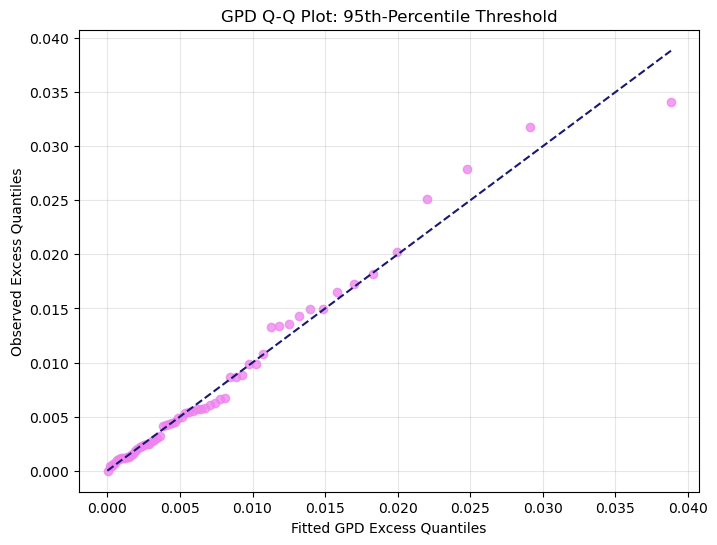

In [44]:
# Chronologically, this cell follows the VaR and ES calculations below; however, I thought it would be easier to follow the notebook's flow to have it here; and it does not require the VaR or ES values below.
# Next, I'm going to inspect the fit visually.
# I'll use a quantile-quantile (Q-Q) plot (inspired by my ADMS 4370 course), in order to compare the observed excesses with what the fitted GPD predicts.
import matplotlib.pyplot as plt

# Ordering the observed excesses from smallest to largest.
observed_excesses = np.sort(excesses.to_numpy())

# Plotting positions for the corresponding fitted GPD quantiles.
probabilities = (np.arange(1, len(observed_excesses) + 1) - 0.5) / len(observed_excesses)

fitted_excesses = genpareto.ppf(
    probabilities,
    c=shape,
    loc=0,
    scale=scale,
)

plt.figure(figsize=(8, 6))
plt.scatter(fitted_excesses, observed_excesses, alpha=0.75, color="violet")

# Reference Line: perfect agreement. 
line_end = max(fitted_excesses.max(), observed_excesses.max())
plt.plot([0, line_end], [0, line_end], color="midnightblue", linestyle="--")

plt.title("GPD Q-Q Plot: 95th-Percentile Threshold")
plt.xlabel("Fitted GPD Excess Quantiles")
plt.ylabel("Observed Excess Quantiles")
plt.grid(alpha=0.3)
plt.savefig("GPD_QQ Plot_95_Ptile.png", dpi=600, bbox_inches="tight")
plt.show()

In [17]:
# GPD fit ran successfully.
# Notebook now has the intended 1,226 complete observations through October 7. 
# At the 95th-percentile threshold:
## Threshold: 1.6207% portfolio loss
## Exceedances: 62
## GPD shape: 0.0509
## GPD scale: 0.007107
# Basic validation checks both passed; the estimated shape is below 1, meaning the fitted GPD has a finite model-implied ES. This does not automatically establish that the tail model fits well - will assess that separately.

# Calculating one-day EVT VaR and ES at 99% confidence.
confidence_level = 0.99
portfolio_value = 5_000_000

n = len(losses)
n_exceedances = len(excesses)
exceedance_probability = n_exceedances / n
tail_probability = 1 - confidence_level

if tail_probability >= exceedance_probability:
    raise ValueError("The requested VaR must lie above the EVT threshold.")

if shape >= 1:
    raise ValueError("The fitted GPD does not have a finite expected shortfall.")

# GPD quantile for the proportion of the fitted tail above the desired VaR
evt_var = threshold + genpareto.isf(
    tail_probability / exceedance_probability,
    c=shape,
    loc=0,
    scale=scale,
)

evt_es = (evt_var + scale - shape * threshold) / (1 - shape)

print(f"One-day {confidence_level:.0%} EVT VaR: "
      f"{evt_var:.2%} (${evt_var * portfolio_value:,.0f})")

print(f"One-day {confidence_level:.0%} EVT ES: "
      f"{evt_es:.2%} (${evt_es * portfolio_value:,.0f})")

One-day 99% EVT VaR: 2.82% ($141,075)
One-day 99% EVT ES: 3.63% ($181,736)


In [18]:
# Above are estimates for one trading day, expressed relative to the initial $5 million portfolio.
# The ES is the estimated average loss among outcomes worse than the 99% VaR; not necessarily a maximum possible loss.
# I'm going to check sensitivity relative to the threshold, by repeating the fit at the 90th, 95th, and 97.5th percentiles and comparing the estimated shape, VaR, and ES. Large diferences would be a finding worth reporting.


# Recording the outputs below:

## At threshold_percentile = 0.975
### Threshold: 2.1109%
### Number of exceedances: 31
### Exceedance proportion: 2.53%
### Shape (xi): -0.0006
### Scale (beta): 0.007901
### Validation checks: passed
### One-day 99% EVT VaR: 2.84% ($142,177)
### One-day 99% EVT ES: 3.63% ($181,632)

## At threshold_percentile = 0.95
### Threshold: 1.6207%
### Exceedances: 62
### Exceedance proportion: 5.06%
### Shape (xi): 0.0509
### Scale (beta): 0.007107
### Validation checks: Passed
### One-day 99% EVT VaR: 2.82% ($141,075)
### One-day 99% EVT ES: 3.63% ($181,736)

## At threshold_percentile = 0.90
### Threshold: 1.1815%
### Exceedances: 123
### Exceedance proportion: 10.03%
### Shape (xi): 0.0817
### Scale (beta): 0.006401
### Validation checks: Passed
### One-day 99% EVT VaR: 2.81% ($140,286)
### One-day 99% EVT ES: 3.65% ($182,367)

# The VaR estimates vary by approximately $1,900 across the three thresholds, and ES varies by approximately $735.
# The estimates appear relatively stable over these particular choices. The 97.5% fit uses only 31 observations, though, so it carries substantial estimation uncertainty.
# I am going to preliminarily conclude that the 95% fit is a reasonable working choice: it lies between the other thresholds and uses 62 observations.